In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

In [3]:
import glob

URL = ("https://raw.githubusercontent.com/afaq-ahmad/"
       "Hotel-booking-demand-Case-Study/master/H2.csv")

def find_path():
    hits = glob.glob("/kaggle/input/**/H2.csv", recursive=True)
    return hits[0] if hits else URL   # falls back to download (needs Internet ON)

def load_raw(drop_duplicates=False):
    df = pd.read_csv(find_path())
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()          # remove padding spaces
    df = df.replace("NULL", np.nan)            # 'NULL' strings are real missing values
    if drop_duplicates:
        df = df.drop_duplicates().reset_index(drop=True)
    return df

raw = load_raw(drop_duplicates=False)
dedup = load_raw(drop_duplicates=True)
print("raw:", raw.shape, "| dedup:", dedup.shape)
print("duplicates removed:", len(raw) - len(dedup))

raw: (79330, 31) | dedup: (53428, 31)
duplicates removed: 25902


In [4]:
display(raw.head())
print(raw.columns.tolist())

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,6,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NaN,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NaN,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NaN,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NaN,0,Transient,76.5,0,1,Canceled,2015-04-02


['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate']


In [5]:
schema = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
})
display(schema)

,dtype,missing,missing_%,unique
IsCanceled,int64,0,0.00,2
LeadTime,int64,0,0.00,453
ArrivalDateYear,int64,0,0.00,3
ArrivalDateMonth,object,0,0.00,12
ArrivalDateWeekNumber,int64,0,0.00,53
ArrivalDateDayOfMonth,int64,0,0.00,31
StaysInWeekendNights,int64,0,0.00,14
StaysInWeekNights,int64,0,0.00,29
Adults,int64,0,0.00,5
Children,float64,4,0.01,4


,rows,cancel_rate_%,mean_ADR
raw,79330,41.73,105.30
dedup,53428,30.04,110.99


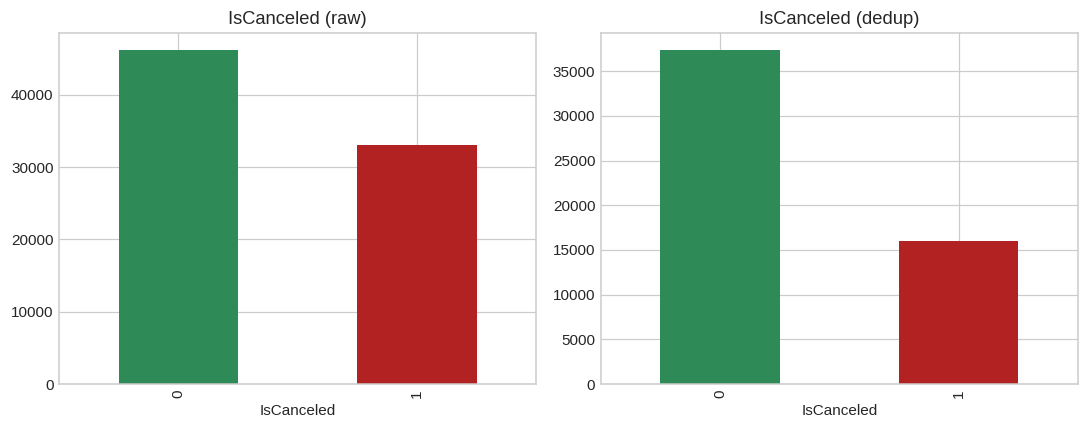

In [6]:
cmp = pd.DataFrame({
    "rows": [len(raw), len(dedup)],
    "cancel_rate_%": [raw.IsCanceled.mean() * 100, dedup.IsCanceled.mean() * 100],
    "mean_ADR": [raw.ADR.mean(), dedup.ADR.mean()],
}, index=["raw", "dedup"]).round(2)
display(cmp)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, d) in zip(ax, [("raw", raw), ("dedup", dedup)]):
    d.IsCanceled.value_counts().sort_index().plot.bar(ax=a, color=["seagreen", "firebrick"])
    a.set_title(f"IsCanceled ({name})")
plt.tight_layout(); plt.show()

In [7]:
d = dedup.copy()
zero_guests = (d.Adults.fillna(0) + d.Children.fillna(0) + d.Babies.fillna(0) == 0)
zero_nights = (d.StaysInWeekendNights + d.StaysInWeekNights == 0)
print("zero guests:", zero_guests.sum())
print("zero nights:", zero_nights.sum())
print("ADR == 0:", (d.ADR == 0).sum(), "| ADR >= 1000:", (d.ADR >= 1000).sum(), "| ADR < 0:", (d.ADR < 0).sum())

zero guests: 154
zero nights: 288
ADR == 0: 1077 | ADR >= 1000: 1 | ADR < 0: 0


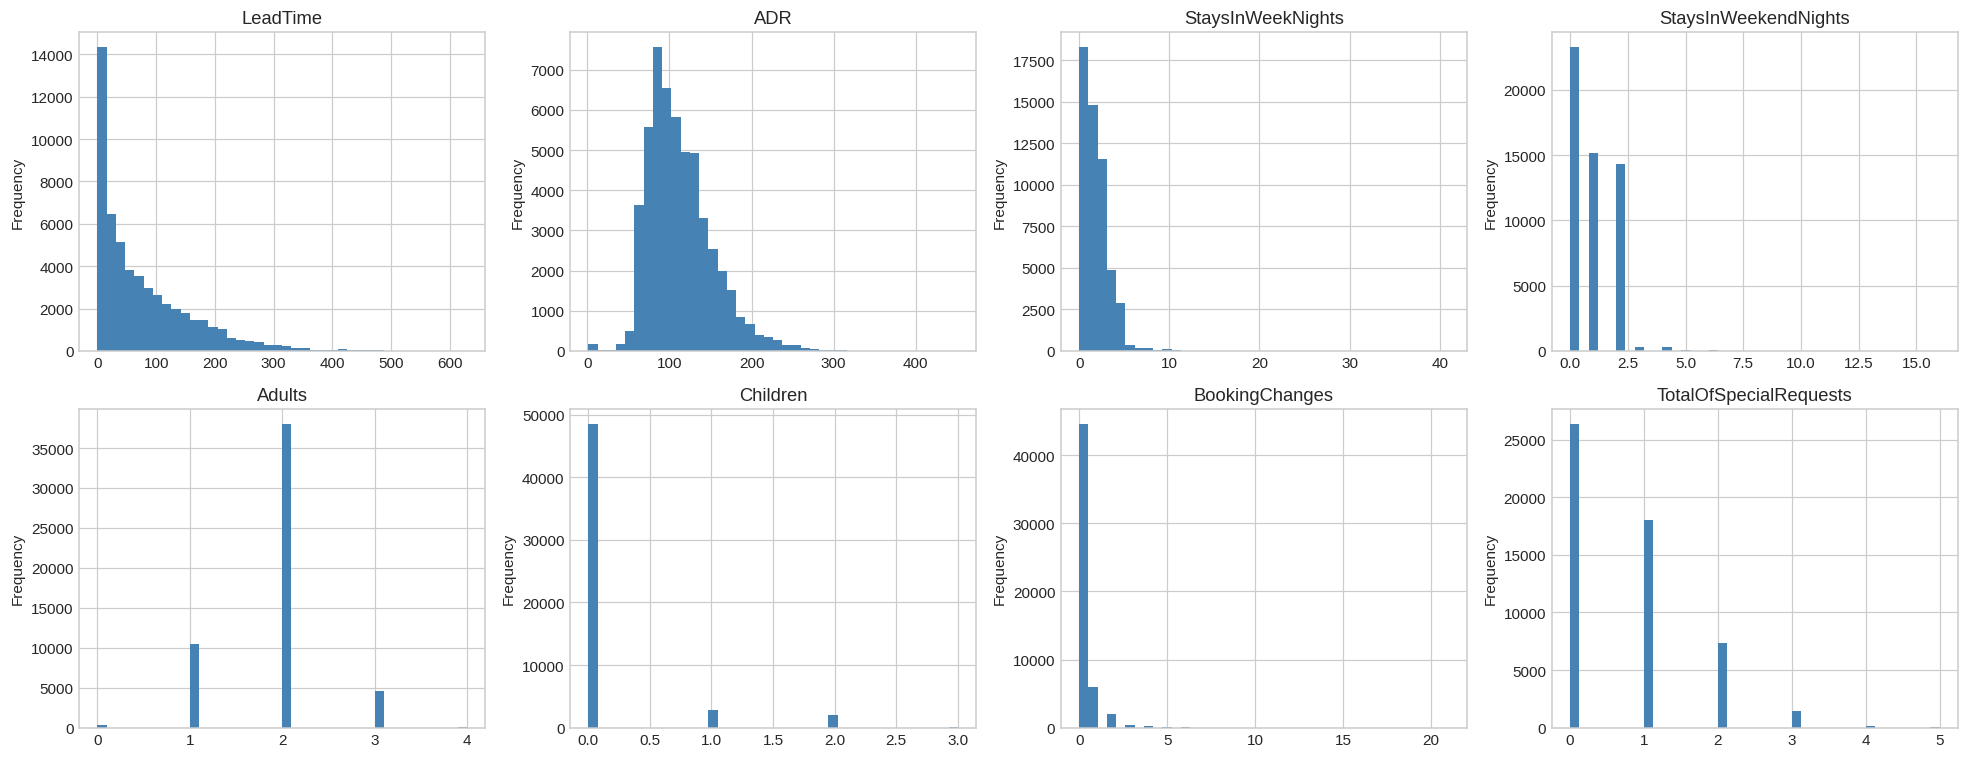

In [8]:
num = ["LeadTime", "ADR", "StaysInWeekNights", "StaysInWeekendNights",
       "Adults", "Children", "BookingChanges", "TotalOfSpecialRequests"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for a, c in zip(axes.ravel(), num):
    s = dedup[c].dropna()
    if c == "ADR":
        s = s[s.between(1, 500)]
    s.plot.hist(bins=40, ax=a, color="steelblue")
    a.set_title(c)
plt.tight_layout(); plt.show()

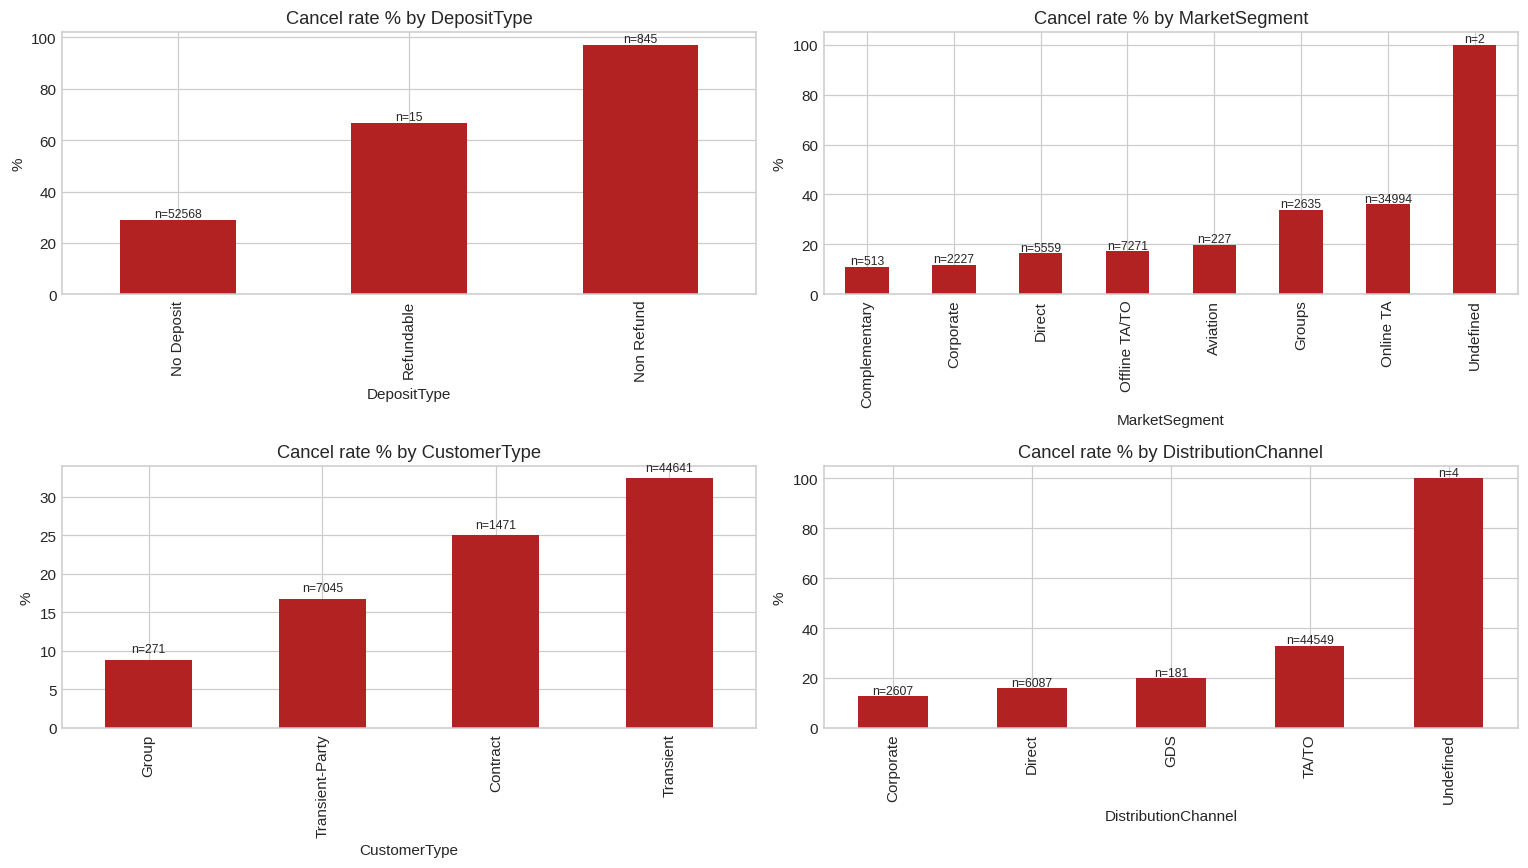

In [9]:
cats = ["DepositType", "MarketSegment", "CustomerType", "DistributionChannel"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, c in zip(axes.ravel(), cats):
    r = dedup.groupby(c).IsCanceled.agg(["mean", "count"]).sort_values("mean")
    (r["mean"] * 100).plot.bar(ax=a, color="firebrick")
    a.set_title(f"Cancel rate % by {c}"); a.set_ylabel("%")
    for i, (m, n) in enumerate(zip(r["mean"], r["count"])):
        a.text(i, m * 100 + 1, f"n={n}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
display(pd.crosstab(dedup.ReservationStatus, dedup.IsCanceled, margins=True))
display(pd.crosstab(dedup.RequiredCarParkingSpaces, dedup.IsCanceled, margins=True))

IsCanceled,0,1,All
ReservationStatus,,,
Canceled,0,15301,15301
Check-Out,37379,0,37379
No-Show,0,748,748
All,37379,16049,53428


IsCanceled,0,1,All
RequiredCarParkingSpaces,,,
0,35483,16049,51532
1,1891,0,1891
2,3,0,3
3,2,0,2
All,37379,16049,53428


,days_alive,TotalOfSpecialRequests,BookingChanges,DaysInWaitingList,LeadTime
days_alive,1.000,0.150,0.110,0.114,0.520
TotalOfSpecialRequests,0.150,1.000,0.050,-0.097,-0.008
BookingChanges,0.110,0.050,1.000,-0.016,0.046
DaysInWaitingList,0.114,-0.097,-0.016,1.000,0.122
LeadTime,0.520,-0.008,0.046,0.122,1.000


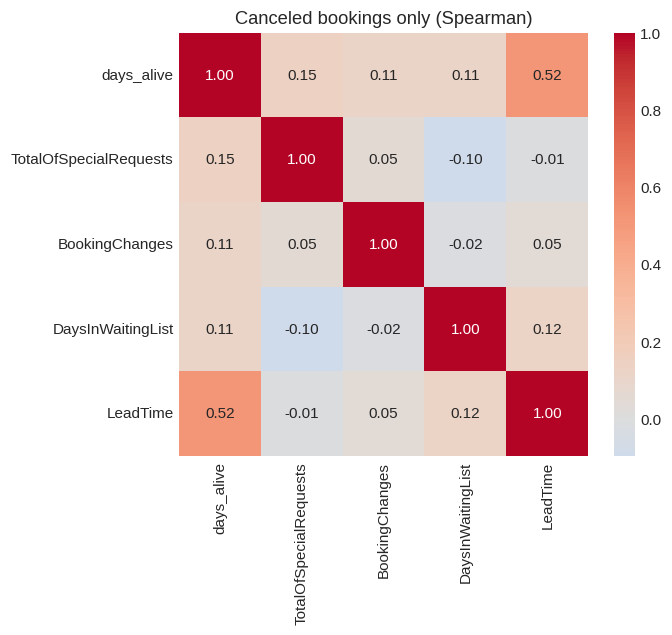

In [11]:
months = {m: i for i, m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], 1)}
d = dedup.copy()
arrival = pd.to_datetime(dict(year=d.ArrivalDateYear,
                              month=d.ArrivalDateMonth.map(months),
                              day=d.ArrivalDateDayOfMonth))
booked = arrival - pd.to_timedelta(d.LeadTime, unit="D")
d["days_alive"] = (pd.to_datetime(d.ReservationStatusDate) - booked).dt.days

c = d[d.IsCanceled == 1]
cols = ["days_alive", "TotalOfSpecialRequests", "BookingChanges", "DaysInWaitingList", "LeadTime"]
corr = c[cols].corr(method="spearman")
display(corr.round(3))
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Canceled bookings only (Spearman)"); plt.show()

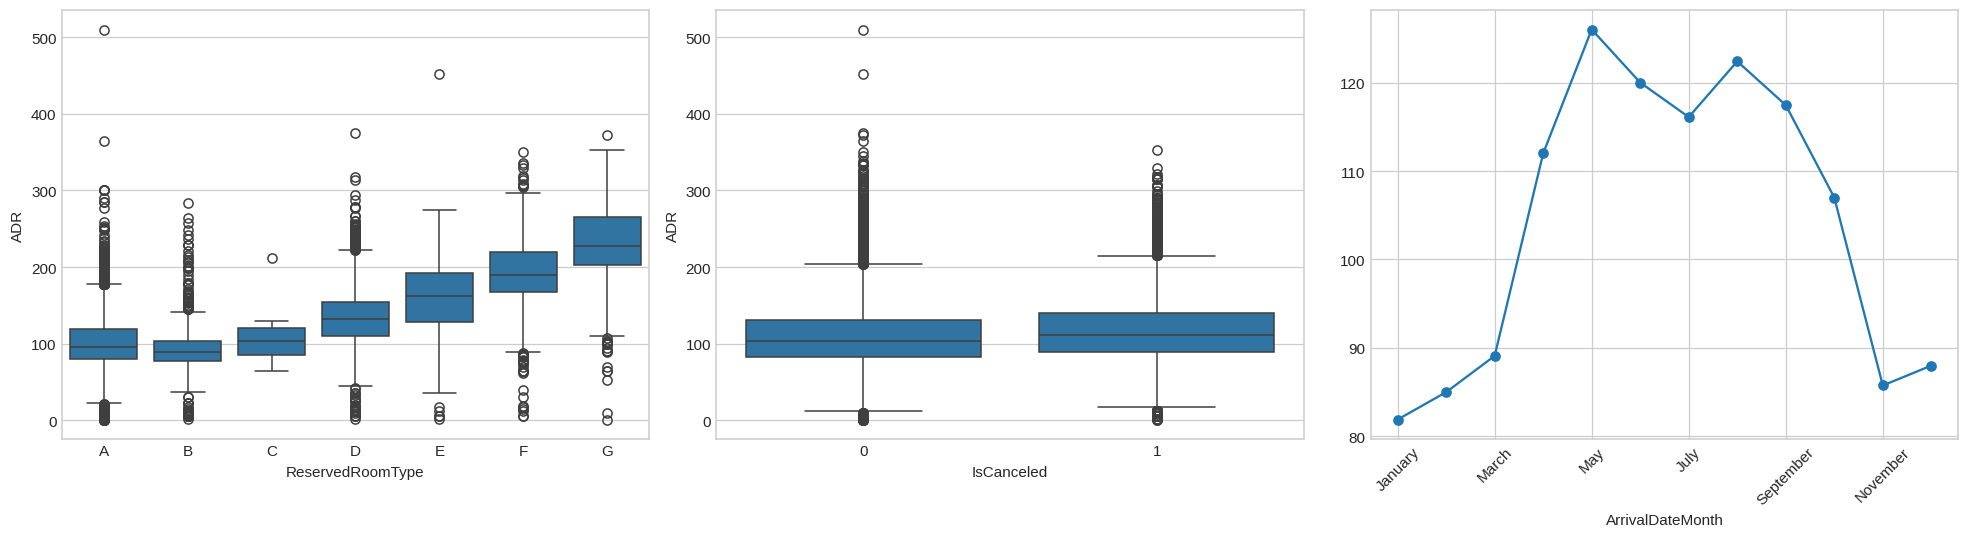

In [12]:
r = dedup[dedup.ADR.between(1, 1000)]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=r, x="ReservedRoomType", y="ADR", order=sorted(r.ReservedRoomType.unique()), ax=axes[0])
sns.boxplot(data=r, x="IsCanceled", y="ADR", ax=axes[1])
r.groupby("ArrivalDateMonth").ADR.median().reindex(list(months)).plot(marker="o", ax=axes[2])
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
LeadTime,53428.0,77.68,82.11,0.0,14.0,50.0,118.0,629.0
ADR,53428.0,110.99,48.06,0.0,84.0,105.3,134.0,5400.0
StaysInWeekendNights,53428.0,0.87,0.91,0.0,0.0,1.0,2.0,16.0
StaysInWeekNights,53428.0,2.27,1.62,0.0,1.0,2.0,3.0,41.0
Adults,53428.0,1.88,0.54,0.0,2.0,2.0,2.0,4.0
Children,53424.0,0.13,0.44,0.0,0.0,0.0,0.0,3.0


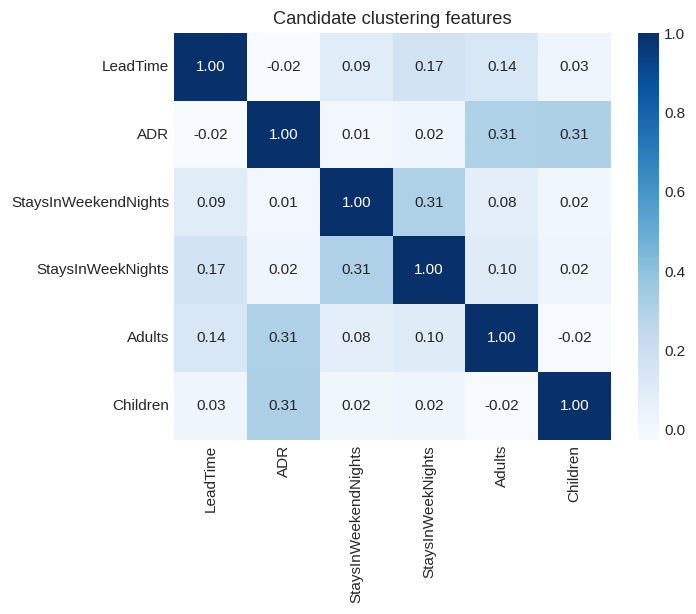

In [13]:
cf = ["LeadTime", "ADR", "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children"]
display(dedup[cf].describe().T.round(2))
sns.heatmap(dedup[cf].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Candidate clustering features"); plt.show()

In [14]:
CFG = {
    "seed": 42,
    "test_size": 0.20,
    "cv_folds": 5,

    # cleaning rules (fixed up front, not tuned on results)
    "drop_duplicates": True,
    "drop_zero_guests": True,
    "drop_zero_nights": True,
    "adr_min_exclusive": 0,       # regression only: ADR must be > 0
    "adr_max_exclusive": 1000,    # regression only: ADR must be < 1000

    # rare-level grouping: level kept if it has at least min_count rows in TRAIN
    "rare_min_count": {
        "Country": 300, "Agent": 300, "Company": 300,
        "MarketSegment": 50, "DistributionChannel": 50,
        "ReservedRoomType": 50, "Meal": 50, "CustomerType": 50,
    },

    # columns dropped for ALL tasks (target restatement or post-booking info)
    "drop_all": ["ReservationStatus", "ReservationStatusDate",
                 "AssignedRoomType", "RequiredCarParkingSpaces",
                 "TotalOfSpecialRequests", "BookingChanges", "DaysInWaitingList"],
}

In [15]:
def clean(df, task):
    d = df.copy()
    if CFG["drop_duplicates"]:
        d = d.drop_duplicates()
    guests = d.Adults.fillna(0) + d.Children.fillna(0) + d.Babies.fillna(0)
    nights = d.StaysInWeekendNights + d.StaysInWeekNights
    if CFG["drop_zero_guests"]:
        d = d[guests.loc[d.index] > 0]
    if CFG["drop_zero_nights"]:
        d = d[nights.loc[d.index] > 0]
    if task == "regression":
        d = d[(d.ADR > CFG["adr_min_exclusive"]) & (d.ADR < CFG["adr_max_exclusive"])]
    d["Children"] = d["Children"].fillna(0)          # only 4 missing: treat as no children
    d["Company"] = d["Company"].fillna("None")       # NULL means no company
    d["Agent"] = d["Agent"].fillna("None")           # NULL means no agent (direct)
    d["Country"] = d["Country"].fillna("Other")      # 24 missing
    d = d.replace("Undefined", "Other")              # MarketSegment / DistributionChannel
    return d.reset_index(drop=True)

for task in ["classification", "regression", "clustering"]:
    print(task, clean(raw, task).shape)

classification (53043, 31)
regression (52320, 31)
clustering (53043, 31)


In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class RareGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, min_count=None):
        self.min_count = min_count            # dict: column -> minimum rows

    def fit(self, X, y=None):
        self.keep_ = {}
        for col, m in self.min_count.items():
            counts = X[col].astype(str).value_counts()
            self.keep_[col] = set(counts[counts >= m].index)
        return self

    def transform(self, X):
        X = X.copy()
        for col, keep in self.keep_.items():
            s = X[col].astype(str)
            X[col] = s.where(s.isin(keep), "Other")
        return X

In [17]:
def other_report(grouper, X_train):
    rows = []
    for col, keep in grouper.keep_.items():
        s = X_train[col].astype(str)
        total_levels = s.nunique()
        merged = ~s.isin(keep)
        rows.append({
            "column": col,
            "levels_total": total_levels,
            "levels_kept": len(keep),
            "levels_merged_to_Other": total_levels - len(keep),
            "rows_in_Other": int(merged.sum()),
            "rows_in_Other_%": round(merged.mean() * 100, 2),
        })
    return pd.DataFrame(rows)

# quick demo on the full classification table (the real fit happens on TRAIN in Cell 17)
demo = clean(raw, "classification")
g = RareGrouper(CFG["rare_min_count"]).fit(demo)
display(other_report(g, demo))

,column,levels_total,levels_kept,levels_merged_to_Other,rows_in_Other,rows_in_Other_%
0,Country,167,22,145,4151,7.83
1,Agent,224,13,211,5770,10.88
2,Company,204,2,202,1901,3.58
3,MarketSegment,8,7,1,2,0.00
4,DistributionChannel,5,4,1,4,0.01
5,ReservedRoomType,7,6,1,13,0.02
6,Meal,4,3,1,11,0.02
7,CustomerType,4,4,0,0,0.00


In [18]:
from sklearn.model_selection import train_test_split
import json

base = clean(raw, "classification")
base["row_id"] = base.index

train_ids, test_ids = train_test_split(
    base["row_id"], test_size=CFG["test_size"],
    random_state=CFG["seed"], stratify=base["IsCanceled"])

with open("split_indices.json", "w") as f:
    json.dump({"seed": CFG["seed"],
               "train_ids": sorted(train_ids.tolist()),
               "test_ids": sorted(test_ids.tolist())}, f)

is_train = base["row_id"].isin(set(train_ids))
reg_ok = (base.ADR > CFG["adr_min_exclusive"]) & (base.ADR < CFG["adr_max_exclusive"])
assert reg_ok.sum() == len(clean(raw, "regression"))   # same rows as Cell 14

summary = pd.DataFrame({
    "classification": [is_train.sum(), (~is_train).sum()],
    "regression": [(is_train & reg_ok).sum(), (~is_train & reg_ok).sum()],
}, index=["train", "test"])
display(summary)
print("cancel rate % train / test:",
      round(base[is_train].IsCanceled.mean() * 100, 2),
      round(base[~is_train].IsCanceled.mean() * 100, 2))

,classification,regression
train,42434,41862
test,10609,10458


cancel rate % train / test: 30.2 30.21


In [19]:
common = [c for c in base.columns
          if c not in CFG["drop_all"] + ["row_id", "IsCanceled", "ADR"]]
# note: IsRepeatedGuest and PreviousBookingsNotCanceled correlate 0.78, both kept for now

FEATURES = {
    "classification": common,      # ADR excluded (tested later as an ablation)
    "regression": common,          # target is ADR, IsCanceled excluded
    "clustering": ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights",
                   "Adults", "Children", "MarketSegment", "CustomerType"],   # ADR only interprets
}

FORBIDDEN = {"ReservationStatus", "ReservationStatusDate", "AssignedRoomType",
             "RequiredCarParkingSpaces", "TotalOfSpecialRequests",
             "BookingChanges", "DaysInWaitingList"}

for task, cols in FEATURES.items():
    assert not (FORBIDDEN & set(cols)), f"leak in {task}"
    assert "IsCanceled" not in cols, f"target in {task}"
    print(task, len(cols), "features:", cols, "\n")
assert "ADR" not in FEATURES["classification"] and "ADR" not in FEATURES["regression"]
print("leakage check passed")

# the Other table for the report, now fitted on TRAIN only
X_train = base.loc[is_train, FEATURES["classification"]]
grouper = RareGrouper(CFG["rare_min_count"]).fit(X_train)
display(other_report(grouper, X_train))

classification 22 features: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType'] 

regression 22 features: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType'] 

clustering 7 features: ['LeadTime', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'MarketSegment', 'CustomerType'] 

leakage check passed


,column,levels_total,levels_kept,levels_merged_to_Other,rows_in_Other,rows_in_Other_%
0,Country,162,20,142,3889,9.16
1,Agent,215,11,204,5178,12.20
2,Company,189,2,187,1513,3.57
3,MarketSegment,8,7,1,2,0.00
4,DistributionChannel,5,4,1,2,0.00
5,ReservedRoomType,7,6,1,8,0.02
6,Meal,4,3,1,8,0.02
7,CustomerType,4,4,0,0,0.00


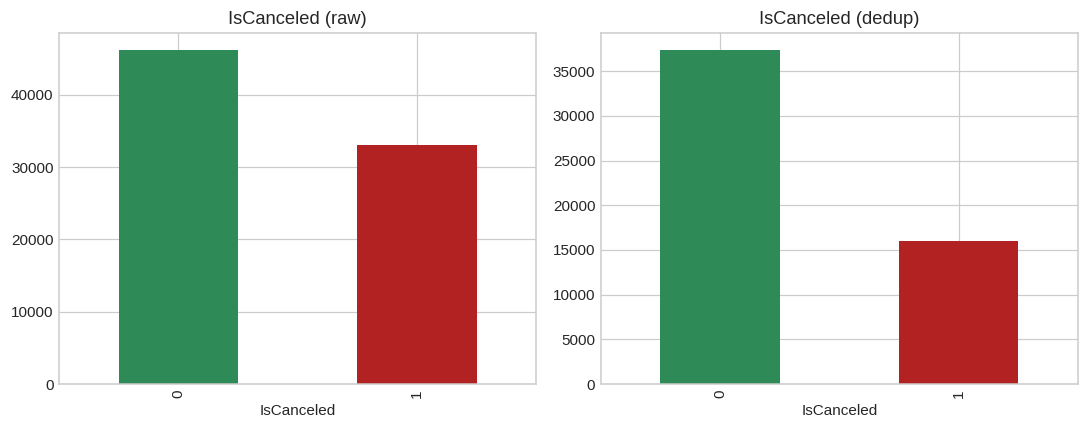

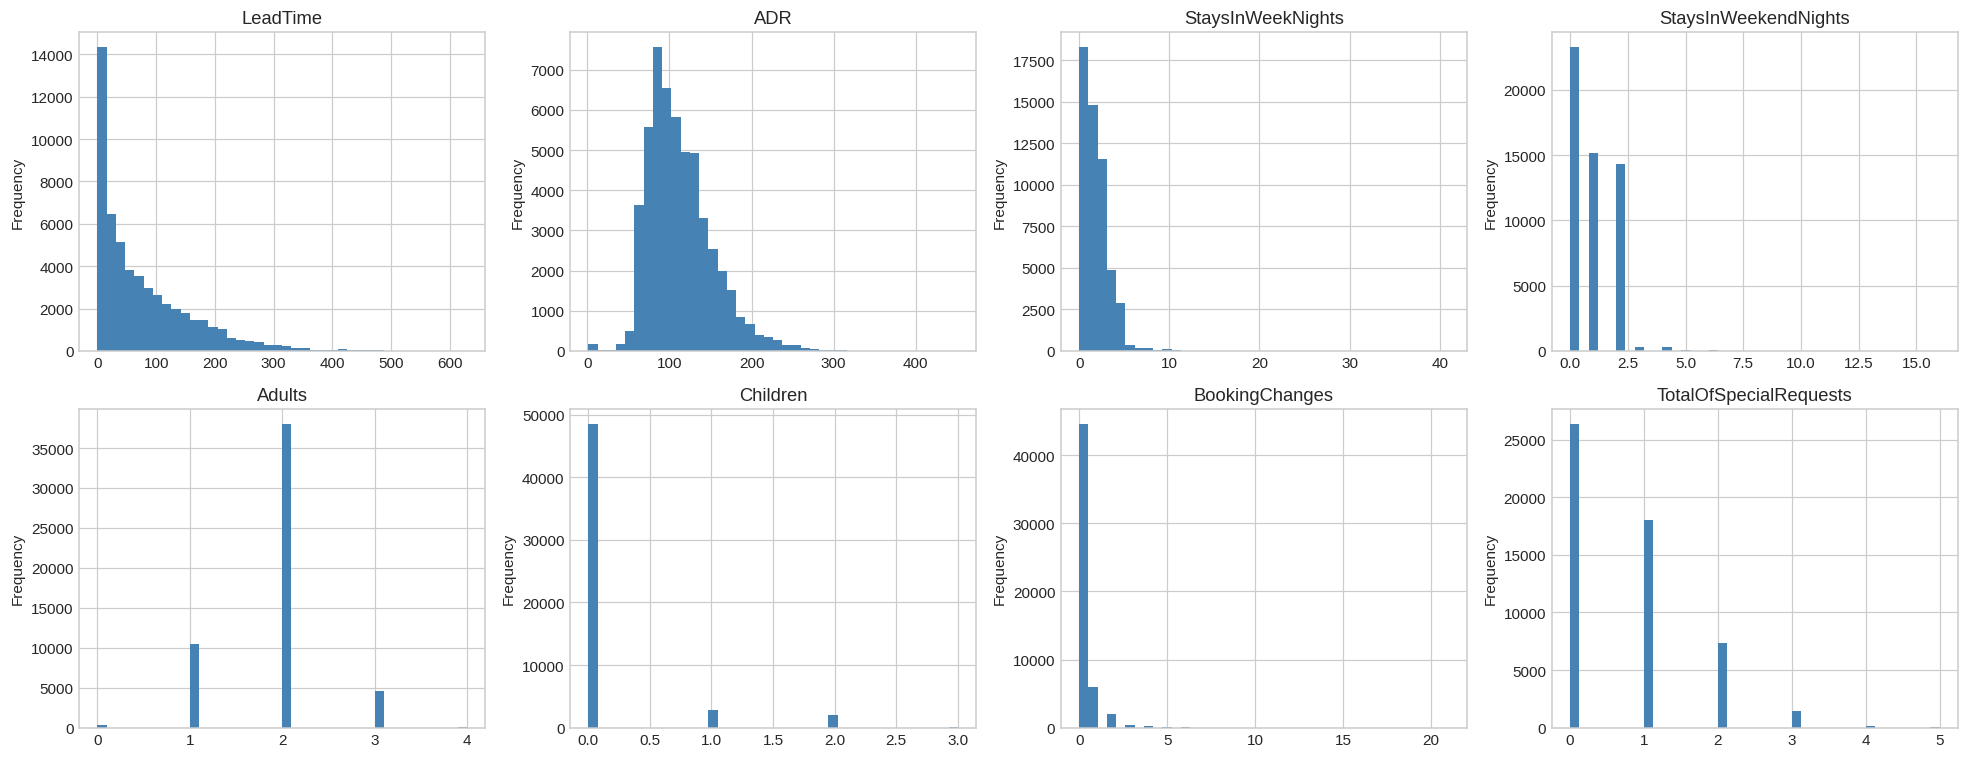

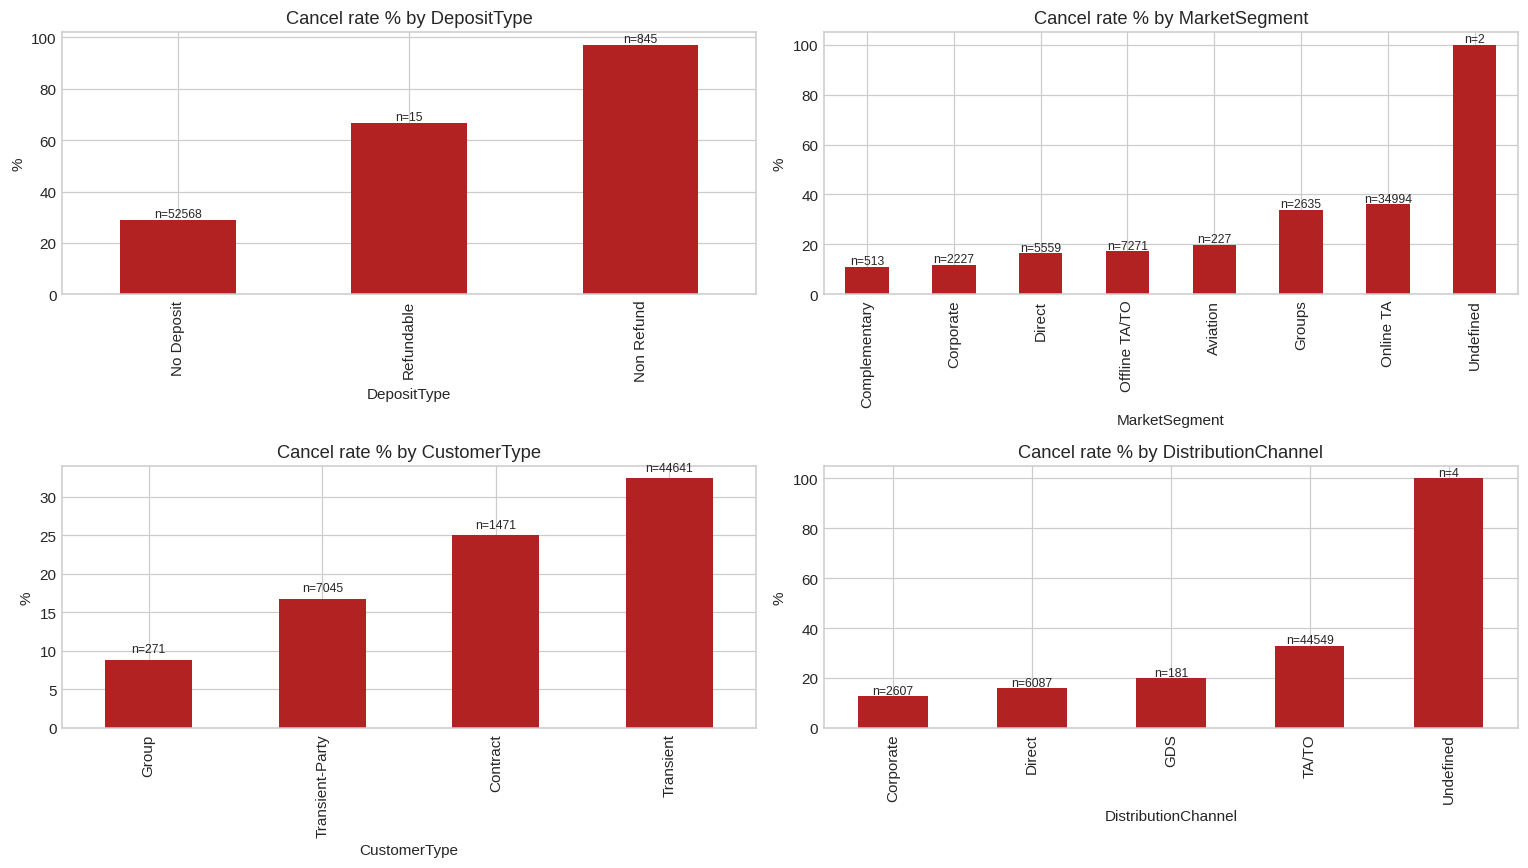

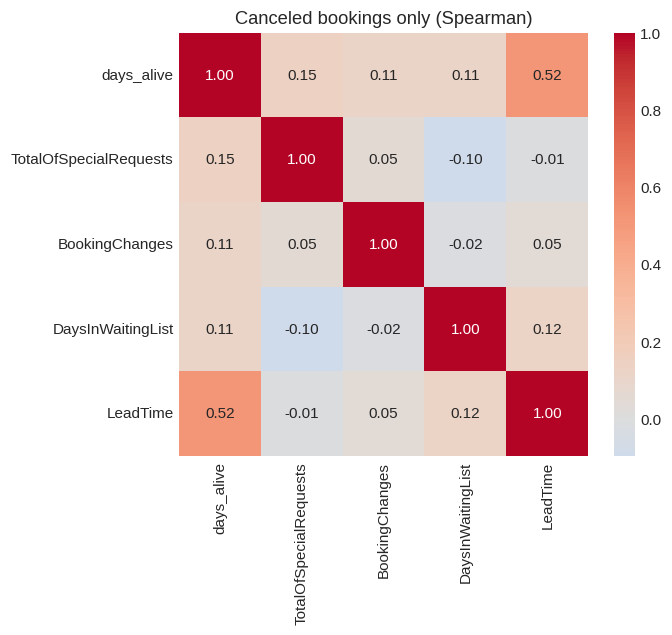

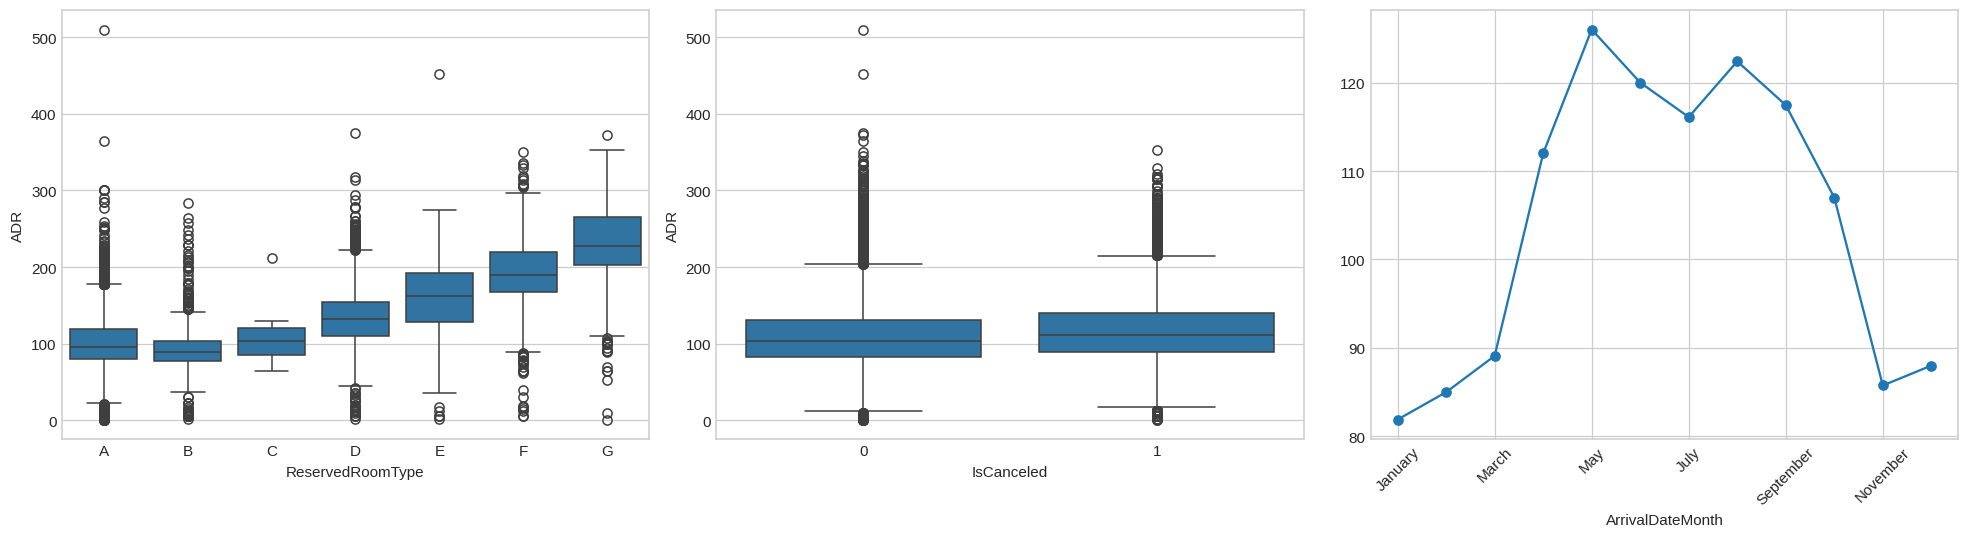

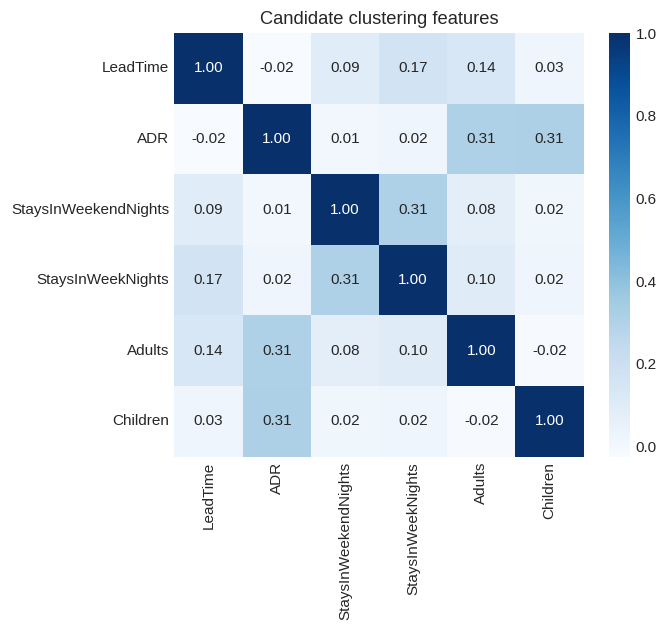

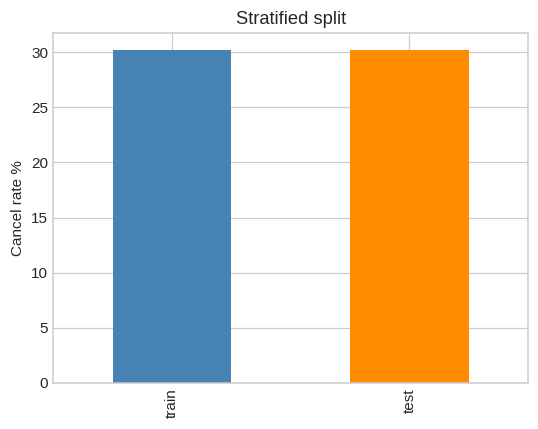

['fig_adr_drivers.png', 'fig_cancel_by_category.png', 'fig_cluster_features.png', 'fig_distributions.png', 'fig_lifecycle_corr.png', 'fig_split_balance.png', 'fig_target_balance.png']


In [23]:
import os, shutil
os.makedirs("figures", exist_ok=True)

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# fig_target_balance: raw vs deduplicated cancellation counts (Cell 5)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, d) in zip(ax, [("raw", raw), ("dedup", dedup)]):
    d.IsCanceled.value_counts().sort_index().plot.bar(ax=a, color=["seagreen", "firebrick"])
    a.set_title(f"IsCanceled ({name})"); a.set_xlabel("IsCanceled")
plt.tight_layout(); save(fig, "fig_target_balance")

# fig_distributions: numeric distributions (Cell 7)
num = ["LeadTime", "ADR", "StaysInWeekNights", "StaysInWeekendNights",
       "Adults", "Children", "BookingChanges", "TotalOfSpecialRequests"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for a, c in zip(axes.ravel(), num):
    s = dedup[c].dropna()
    if c == "ADR":
        s = s[s.between(1, 500)]
    s.plot.hist(bins=40, ax=a, color="steelblue"); a.set_title(c)
plt.tight_layout(); save(fig, "fig_distributions")

# fig_cancel_by_category: cancel rate by category, deduplicated (Cell 8)
cats = ["DepositType", "MarketSegment", "CustomerType", "DistributionChannel"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, c in zip(axes.ravel(), cats):
    r = dedup.groupby(c).IsCanceled.agg(["mean", "count"]).sort_values("mean")
    (r["mean"] * 100).plot.bar(ax=a, color="firebrick")
    a.set_title(f"Cancel rate % by {c}"); a.set_ylabel("%")
    for i, (m, n) in enumerate(zip(r["mean"], r["count"])):
        a.text(i, m * 100 + 1, f"n={n}", ha="center", fontsize=8)
plt.tight_layout(); save(fig, "fig_cancel_by_category")

# fig_lifecycle_corr: lifecycle leakage test (Cell 10)
months = {m: i for i, m in enumerate(
    ["January","February","March","April","May","June","July",
     "August","September","October","November","December"], 1)}
d = dedup.copy()
arrival = pd.to_datetime(dict(year=d.ArrivalDateYear,
                              month=d.ArrivalDateMonth.map(months),
                              day=d.ArrivalDateDayOfMonth))
booked = arrival - pd.to_timedelta(d.LeadTime, unit="D")
d["days_alive"] = (pd.to_datetime(d.ReservationStatusDate) - booked).dt.days
cols = ["days_alive", "TotalOfSpecialRequests", "BookingChanges", "DaysInWaitingList", "LeadTime"]
corr = d[d.IsCanceled == 1][cols].corr(method="spearman")
fig = plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Canceled bookings only (Spearman)")
save(fig, "fig_lifecycle_corr")

# fig_adr_drivers: ADR relationships (Cell 11)
r = dedup[dedup.ADR.between(1, 1000)]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=r, x="ReservedRoomType", y="ADR", order=sorted(r.ReservedRoomType.unique()), ax=axes[0])
sns.boxplot(data=r, x="IsCanceled", y="ADR", ax=axes[1])
r.groupby("ArrivalDateMonth").ADR.median().reindex(list(months)).plot(marker="o", ax=axes[2])
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); save(fig, "fig_adr_drivers")

# fig_cluster_features: candidate clustering features (Cell 12)
cf = ["LeadTime", "ADR", "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children"]
fig = plt.figure(figsize=(6, 5))
sns.heatmap(dedup[cf].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Candidate clustering features")
save(fig, "fig_cluster_features")

# fig_split_balance: class balance in train vs test (Cell 17)
fig, ax = plt.subplots(figsize=(5, 4))
bal = pd.Series({"train": base[is_train].IsCanceled.mean() * 100,
                 "test": base[~is_train].IsCanceled.mean() * 100})
bal.plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set_ylabel("Cancel rate %"); ax.set_title("Stratified split")
plt.tight_layout(); save(fig, "fig_split_balance")

shutil.make_archive("figures", "zip", "figures")
print(sorted(os.listdir("figures")))

In [22]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

cl = clean(raw, "clustering")

# two combined features that summarise the stay and the party
cl["TotalNights"] = cl.StaysInWeekendNights + cl.StaysInWeekNights
cl["TotalGuests"] = cl.Adults + cl.Children + cl.Babies

CLUSTER_NUM = ["LeadTime", "TotalNights", "TotalGuests", "Children"]
CLUSTER_CAT = ["MarketSegment", "CustomerType"]
CLUSTER_INPUT = CLUSTER_NUM + CLUSTER_CAT

# leakage guard: no outcome, no status, no price, no lifecycle column
BANNED = {"IsCanceled", "ADR", "ReservationStatus", "ReservationStatusDate",
          "AssignedRoomType", "RequiredCarParkingSpaces",
          "TotalOfSpecialRequests", "BookingChanges", "DaysInWaitingList"}
assert not (BANNED & set(CLUSTER_INPUT)), "leak in clustering input"

# rare levels grouped first, then one-hot for categories and scaling for numbers
grouped = RareGrouper({c: CFG["rare_min_count"][c] for c in CLUSTER_CAT}).fit(cl[CLUSTER_CAT])
cl[CLUSTER_CAT] = grouped.transform(cl[CLUSTER_CAT])

prep = ColumnTransformer([
    ("num", StandardScaler(), CLUSTER_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CLUSTER_CAT),
])
X_cluster = prep.fit_transform(cl[CLUSTER_INPUT])
print("clustering matrix:", X_cluster.shape)

# profile function: ADR and cancellation describe the groups, they never form them
def profile(df, labels):
    d = df.copy(); d["cluster"] = labels
    out = d.groupby("cluster").agg(
        bookings=("LeadTime", "size"),
        mean_ADR=("ADR", "mean"),
        mean_lead=("LeadTime", "mean"),
        mean_nights=("TotalNights", "mean"),
        mean_guests=("TotalGuests", "mean"),
        top_segment=("MarketSegment", lambda s: s.mode()[0]),
        top_customer=("CustomerType", lambda s: s.mode()[0]),
        cancel_rate_pct=("IsCanceled", lambda s: s.mean() * 100),
    ).round(2)
    return out

clustering matrix: (53043, 16)
